In [ ]:
import sys, io as _io
from pathlib import Path
sys.path.insert(0, str(Path('..').resolve()))

from vnstock import Vnstock
import pandas as pd
import seaborn as sns
from matplotlib import pyplot as plt
import numpy as np
from mpl_toolkits.mplot3d import Axes3D
from dataclasses import dataclass, field
from datetime import datetime
from typing import Optional
from typing import Dict

import sqlite3
import database as db

Phiên bản Vnstock 3.2.3 đã có mặt, vui lòng cập nhật với câu lệnh : `pip install vnstock --upgrade`.
Lịch sử phiên bản: https://vnstocks.com/docs/tai-lieu/lich-su-phien-ban
Phiên bản hiện tại 3.1.0.2

In [ ]:
# ── Data source switch ───────────────────────────────────────────────────
# 'vnstock'  : VN30 index price from TCBS only (original behavior)
# 'db'       : VN30 index price from TCBS + pe_ratio from stock_data.db
#              pe_ratio column becomes available for strategy signals
DATA_SOURCE = 'db'

VNSTOCK_SYMBOL = 'VN30'
VNSTOCK_START  = '2012-01-01'
VNSTOCK_END    = '2026-07-10'


def load_df(source: str) -> pd.DataFrame:
    """
    Returns DataFrame with [time, close] always present.
    'db' source also adds [pe_ratio] from stock_data.db.
    'close' scale matches VN30 index points (~400-1500 range).
    """
    # always fetch price from vnstock
    stock = Vnstock().stock(symbol=VNSTOCK_SYMBOL, source='TCBS')
    df = stock.quote.history(start=VNSTOCK_START, end=VNSTOCK_END, interval='1D')
    df = df.reset_index(drop=True)[['time', 'close']]
    df['time'] = pd.to_datetime(df['time'])

    if source == 'db':
        con = sqlite3.connect(db.DB_PATH)
        pe = pd.read_sql_query(
            'SELECT date, pe_ratio FROM pe_vn30 WHERE pe_ratio IS NOT NULL ORDER BY date',
            con, parse_dates=['date']
        )
        con.close()
        pe = pe.rename(columns={'date': 'time'})
        df = df.merge(pe, on='time', how='left')
        df['pe_ratio'] = df['pe_ratio'].ffill()

    return df

2025-04-13 13:44:06 - vnstock.common.data.data_explorer - WARNING - Nguồn TCBS hiện tại chỉ hỗ trợ các thông tin về giá và giao dịch, không hỗ trợ thông tin công ty.


In [ ]:
df = load_df(DATA_SOURCE)
df = df.reset_index(drop=True)
print(f'Source : {DATA_SOURCE}')
print(f'Rows   : {len(df)}')
print(f'Range  : {df["time"].iloc[0].date()} -> {df["time"].iloc[-1].date()}')
print(f'Close  : {df["close"].min():.0f} - {df["close"].max():.0f}')
df

2025-04-13 13:44:06 - vnstock.explorer.tcbs.quote - ERROR - Dữ liệu không tồn tại từ 2002-03-18 đến 2003-03-17: 'time'
2025-04-13 13:44:06 - vnstock.explorer.tcbs.quote - ERROR - Dữ liệu không tồn tại từ 2003-03-18 đến 2004-03-17: 'time'
2025-04-13 13:44:07 - vnstock.explorer.tcbs.quote - ERROR - Dữ liệu không tồn tại từ 2004-03-18 đến 2005-03-17: 'time'
2025-04-13 13:44:07 - vnstock.explorer.tcbs.quote - ERROR - Dữ liệu không tồn tại từ 2005-03-18 đến 2006-03-17: 'time'
2025-04-13 13:44:07 - vnstock.explorer.tcbs.quote - ERROR - Dữ liệu không tồn tại từ 2006-03-18 đến 2007-03-17: 'time'
2025-04-13 13:44:07 - vnstock.explorer.tcbs.quote - ERROR - Dữ liệu không tồn tại từ 2007-03-18 đến 2008-03-17: 'time'
2025-04-13 13:44:07 - vnstock.explorer.tcbs.quote - ERROR - Dữ liệu không tồn tại từ 2008-03-18 đến 2009-03-17: 'time'
2025-04-13 13:44:07 - vnstock.explorer.tcbs.quote - ERROR - Dữ liệu không tồn tại từ 2009-03-18 đến 2010-03-17: 'time'
2025-04-13 13:44:07 - vnstock.explorer.tcbs.quot

,time,open,high,low,close,volume
0,2012-02-06,447.47,447.47,447.47,447.47,13467070
1,2012-02-07,449.31,449.31,449.31,449.31,17261070
2,2012-02-08,460.98,460.98,460.98,460.98,20406280
3,2012-02-09,464.73,464.73,464.73,464.73,20379320
4,2012-02-10,458.23,458.23,458.23,458.23,20816360
...,...,...,...,...,...,...
3508,2025-03-12,1397.40,1400.45,1387.35,1392.39,268135601
3509,2025-03-13,1393.93,1400.60,1385.24,1387.30,348831063
3510,2025-03-14,1387.08,1394.39,1385.20,1387.03,374746690
3511,2025-03-17,1392.75,1397.28,1389.42,1394.90,352390462


In [4]:
df.iloc[0 : 2]

,time,open,high,low,close,volume
0,2012-02-06,447.47,447.47,447.47,447.47,13467070
1,2012-02-07,449.31,449.31,449.31,449.31,17261070


In [5]:
@dataclass
class RangeDaysClose:
    localTop: float
    localAvg: float
    localBottom: float
    
@dataclass
class IndexCloses:
    rangeDayCloses: dict[int, RangeDaysClose] = field(default_factory=dict)

In [6]:
cal_range_close: dict[int, IndexCloses] = {}

firstRow = df.head(1)
firstClose = firstRow['close'].values[0] * 1000
firstDate = firstRow['time'].values[0]
firstDate = pd.Timestamp(firstDate)

for index, row in df.iterrows():
    close = row['close'] * 1000
    timeCol = row['time']

    cal_range_close[index] = IndexCloses()
    indexCloses = cal_range_close[index]

    for rangeDays in range(1, 101):
        maxDistanceFromPresent = rangeDays if rangeDays < index + 1 else index
        fromIndex = index - maxDistanceFromPresent
        toIndex = index
    
        lastNRows = df.iloc[fromIndex : toIndex]
    
        if not lastNRows.empty:
            max_close_row = lastNRows.loc[lastNRows['close'].idxmax()] 
            localTop = max_close_row['close'] * 1000
            localTopDate = max_close_row['time']

            min_close_row = lastNRows.loc[lastNRows['close'].idxmin()] 
            localBottom = min_close_row['close'] * 1000
            localBttomDate = min_close_row['time']

            avg_close_value = lastNRows['close'].mean()
            localAvg = avg_close_value * 1000

            indexCloses.rangeDayCloses[rangeDays] = RangeDaysClose(
                localTop = localTop,
                localAvg = localAvg,
                localBottom = localBottom
            )
        else:
            localTop = firstClose
            localTopDate = firstDate
            localAvg = firstClose
            localBottom = firstClose

            indexCloses.rangeDayCloses[rangeDays] = RangeDaysClose(
                localTop = localTop,
                localAvg = localAvg,
                localBottom = localBottom
            )
    

In [7]:
cal_range_close[2].rangeDayCloses[2]

RangeDaysClose(localTop=449310.0, localAvg=448390.0, localBottom=447470.0)

In [8]:
totalClose = 0
totalMonths = 0

monthAdd = 0
yearAdd = 0
for index, row in df.iterrows():
    close = row['close'] * 1000
    timeCol = row['time']
    month = timeCol.month;
    year = timeCol.year;
    day = timeCol.day

    if(monthAdd != month or yearAdd != year):
        totalClose += close
        totalMonths += 1
        monthAdd = month
        yearAdd = year

print(totalMonths)
print(totalClose / totalMonths)

170
916459.3529411765


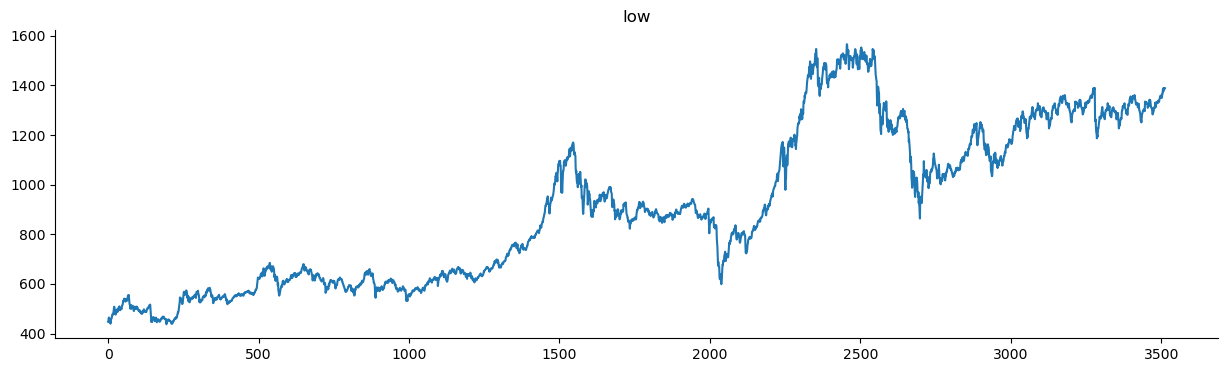

In [11]:

df['low'].plot(kind='line', figsize=(15, 4), title='low')
plt.gca().spines[['top', 'right']].set_visible(False)

In [12]:
@dataclass
class SellInfo:
    index: int = 0
    time: str = ""
    close: float = 0.0
    localBottom: float = 0.0
    localBottomDate: str = ""
    sellStock: float = 0.0
    sellCapital: float = 0.0
    sellFinal: float = 0.0
    sellGrowthRatito: float = 0.0

@dataclass
class ReinvestInfo:
    index: int = 0
    time: str = ""
    close: float = 0.0
    averageProfitPrice: float = 0.0
    reInvestFinal: float = 0.0
    reInvestStock: float = 0.0
    reInvestCapital: float = 0.0

@dataclass
class BuyedInfo:
    index: int = 0
    time: str = ""
    close: float = 0.0
    localTop: float = 0.0
    localTopDate: str = ""
    availableBuyMoney: float = 0.0
    numberOfStockCanBy: float = 0.0
    reinvestFinal: float = 0.0
    reinvestCapital: float = 0.0
    reinvestStockCanBy: float = 0.0

@dataclass
class DepositAddInfo:
    index: int = 0
    time: str = ""
    close: float = 0.0
    availableMoneyInterest: float = 0
    totalProfitInterest: float = 0

class InvestmentTracker:
    def __init__(self):
        self.totalCapital = 0
        self.totalCurrentCapital = 0
        self.totalStock = 0

        self.availableMoney = 0
        self.availableMoneyInterest = 0
        
        self.dateAddMoney = None
        self.dateInvestInterval = None
        self.dateDepositAdded = None
        self.totalMonths = 0
        
        self.totalProfitCapital = 0
        self.totalProfitFinal = 0
        self.totalProfitInterest = 0
        self.totalProfitStock = 0
        
        self.totalReinvestCapital = 0
        self.totalReinvestFinal = 0
        
        self.buyedInfos: list[BuyedInfo] = []
        self.sellInfos: list[SellInfo] = []
        self.reinvestInfos: list[ReinvestInfo] = []
        self.depositAddInfos: list[DepositAddInfo] = []
        

    def add_sell_info(self, info: SellInfo):
        self.sellInfos.append(info)

    def add_reinvest_info(self, info: ReinvestInfo):
        self.reinvestInfos.append(info)

    def add_buyed_info(self, info: BuyedInfo):
        self.buyedInfos.append(info)

    def add_depositAdd_info(self, info: DepositAddInfo):
        self.depositAddInfos.append(info)

In [13]:
class Sellor:
    def sell(self, tracker, sellFinal, index, close, isPrint):
        totalProfit = tracker.totalStock * close

        if(tracker.totalStock <= 0 or tracker.totalCapital <= 0):
            return
        if(sellFinal <= 0):
            return
        
        sellStock = sellFinal * tracker.totalStock / totalProfit
        sellCapital = sellFinal * tracker.totalCapital / totalProfit
        sellCurrentCapital = sellFinal * tracker.totalCurrentCapital / totalProfit
    
        tracker.totalProfitStock += sellStock
        tracker.totalProfitCapital += sellCapital
        tracker.totalProfitFinal += sellFinal
    
        tracker.totalStock -= sellStock
        tracker.totalCapital -= sellCapital
        tracker.totalCurrentCapital -= sellCurrentCapital
        
        sellGrowthRatito = (sellFinal - sellCapital) / sellCapital * 100
        sellcurrentGrowthRatito = (sellFinal - sellCurrentCapital) / sellCurrentCapital * 100
        totalProfitGrowthRatio = (tracker.totalProfitFinal - tracker.totalProfitCapital) / tracker.totalProfitCapital * 100
        sellInfo = SellInfo(
            index=index,
            close=close,
            sellStock=sellStock,
            sellCapital=sellCapital,
            sellFinal=sellFinal,
            sellGrowthRatito=sellGrowthRatito
        )
        tracker.add_sell_info(sellInfo)
    
        if isPrint:
            print(f'''-------------------------------------------------------------''')
            print(f'''sell --- index: {index}, month: {tracker.totalMonths}, close: {close}, sellCapital: {sellCapital}, sellFinal: {sellFinal}, sellStock: {sellStock}, sellGrowthRatito: {sellGrowthRatito}% sellcurrentGrowthRatito: {sellcurrentGrowthRatito}%''')


class Reinvestor:
    def reinvest(self, tracker, reInvestFinal, index, close, isPrint):
        if(tracker.totalProfitStock <= 0):
            return
        
        reInvestStock = reInvestFinal *  tracker.totalProfitStock / tracker.totalProfitFinal
        reInvestCapital = reInvestFinal * tracker.totalProfitCapital / tracker.totalProfitFinal

        tracker.totalProfitStock -= reInvestStock
        tracker.totalProfitCapital -= reInvestCapital
        tracker.totalProfitFinal -= reInvestFinal

        tracker.totalReinvestCapital += reInvestCapital
        tracker.totalReinvestFinal += reInvestFinal

        reinvestAvailableMoneyInterest = tracker.availableMoneyInterest
        tracker.totalReinvestFinal += reinvestAvailableMoneyInterest
        tracker.availableMoneyInterest -= reinvestAvailableMoneyInterest

        reinestTotalProfitInterest = tracker.totalProfitInterest
        tracker.totalReinvestFinal += reinestTotalProfitInterest
        tracker.totalProfitInterest -= reinestTotalProfitInterest

        tracker.add_reinvest_info(ReinvestInfo(
            index=index,
            close=close,
            reInvestFinal=reInvestFinal,
            reInvestStock=reInvestStock,
            reInvestCapital=reInvestCapital,
        ))

        if isPrint:
            print(f'''-------------------------------------------------------------''')
            print(f'reinvest --- index: {index}, month: {tracker.totalMonths}, close: {close}, close {close}, reInvestCapital: {reInvestCapital}, reInvestFinal {reInvestFinal}, reinvestAvailableMoneyInterest {reinvestAvailableMoneyInterest}, reinestTotalProfitInterest {reinestTotalProfitInterest}')

class Buyer:
    def buy(self, tracker, availableBuyMoney, reinvestFinal, index, close, isPrint):
        if(availableBuyMoney > 0):

            tracker.availableMoney -= availableBuyMoney

            tracker.totalCapital += availableBuyMoney
            tracker.totalCurrentCapital += availableBuyMoney
            numberOfStockCanBy = availableBuyMoney / (close)
            tracker.totalStock += numberOfStockCanBy

            tracker.add_buyed_info(BuyedInfo(
                index=index,
                close=close,
                availableBuyMoney=availableBuyMoney,
                numberOfStockCanBy=numberOfStockCanBy,
            ))

        if(reinvestFinal > 0):
            reinvestCapital = reinvestFinal * tracker.totalReinvestCapital / tracker.totalReinvestFinal
            tracker.totalReinvestFinal -= reinvestFinal
            tracker.totalReinvestCapital -= reinvestCapital

            tracker.totalCapital += reinvestCapital
            tracker.totalCurrentCapital += reinvestFinal
            reinvestStockCanBy = reinvestFinal / (close)
            tracker.totalStock += reinvestStockCanBy

            tracker.add_buyed_info(BuyedInfo(
                index=index,
                close=close,
                reinvestFinal=reinvestFinal,
                reinvestCapital=reinvestCapital,
                reinvestStockCanBy=reinvestStockCanBy,
            ))

        # if isPrint and (availableBuyMoney > 0 or reinvestFinal > 0):
        #     print(f'''buy --- index: {index} close: {close}, availableBuyMoney: {availableBuyMoney}, reinvestFinal: {reinvestFinal}''')


class DepositAdder:
    def add(self, tracker, index, depositPercent, now, isPrint):
        month = now.month;
        year = now.year;
        day = now.day;

        
        if tracker.dateDepositAdded == None or (year > tracker.dateDepositAdded.year) or (year == tracker.dateDepositAdded.year and month > tracker.dateDepositAdded.month):
            tracker.dateDepositAdded = now

            availableMoneyInterest = (tracker.availableMoney + tracker.availableMoneyInterest) * (depositPercent / 100) / 12
            tracker.availableMoneyInterest += availableMoneyInterest

            totalProfitInterest = (tracker.totalProfitFinal + tracker.totalProfitInterest) * (depositPercent / 100) / 12
            tracker.totalProfitInterest += totalProfitInterest

            # if isPrint:
            #     print(f'''adddeposit --- index: {index} close: {close}, availableMoneyInterest: {availableMoneyInterest}, totalProfitInterest: {totalProfitInterest}''')
            
            tracker.add_depositAdd_info(DepositAddInfo(
                index=index,
                close=close,
                availableMoneyInterest=availableMoneyInterest,
                totalProfitInterest=totalProfitInterest
            ))

In [14]:
class SellStrategy:
    def considerSell(self, tracker: InvestmentTracker, index, close, cal_range_close, isPrint):
        pass

@dataclass
class SellTopStrategy(SellStrategy):
    percentSell: float = 0
    def considerSell(self, tracker: InvestmentTracker, index, close, cal_range_close, isPrint):
        if(tracker.totalCurrentCapital > 0 and tracker.totalStock > 0):
            totalProfit = tracker.totalStock * close
            increasePercent = (totalProfit - tracker.totalCurrentCapital) / tracker.totalCurrentCapital
            targetPercent = self.percentSell / 100
            deviationPercent = 0
            
            if(increasePercent > targetPercent - deviationPercent):
                sellFinal = totalProfit
                
                sellor = Sellor()
                sellor.sell(tracker, sellFinal, index, close, isPrint)

@dataclass
class SellTopOfBottomStrategy(SellStrategy):
    firstLocalBottom: float
    percentSell: float = 0
    localRangeDays: int = 0
    def considerSell(self, tracker: InvestmentTracker, index, close, cal_range_close, isPrint):
        if(tracker.totalCurrentCapital > 0 and tracker.totalStock > 0):
            localBottom = self.firstLocalBottom
    
            if(index in cal_range_close):
                if(self.localRangeDays in cal_range_close[index].rangeDayCloses):
                    localBottom = cal_range_close[index].rangeDayCloses[self.localRangeDays].localBottom
            increasePercent = (close - localBottom) / localBottom
            targetPercent = self.percentSell / 100
            if(increasePercent > targetPercent):
                totalProfit = tracker.totalStock * close
                sellFinal = totalProfit
                
                sellor = Sellor()
                sellor.sell(tracker, sellFinal, index, close, isPrint)

In [15]:
class ReinvestStrategy:
    def considerReinvest(self, tracker: InvestmentTracker, index, close, cal_range_close, isPrint):
        pass

@dataclass
class ReInvestBottomStrategy(ReinvestStrategy):
    def considerReinvest(self, tracker: InvestmentTracker, index, close, cal_range_close, isPrint):
        if(tracker.totalProfitFinal > 0 and tracker.totalProfitStock > 0):
            averageProfitPrice = tracker.totalProfitFinal / tracker.totalProfitStock
            decreasePercent = (averageProfitPrice - close) / averageProfitPrice
            targetPercent = self.percentReinvest / 100
            deviationPercent = 0
            if(decreasePercent > targetPercent - deviationPercent):
                reInvestFinal = tracker.totalProfitFinal
                
                reinvestor = Reinvestor()
                reinvestor.reinvest(tracker, reInvestFinal, index, close, isPrint)

@dataclass
class ReInvestBottomOfTopStrategy(ReinvestStrategy):
    firstLocalTop: float
    localRangeDays: int = 1
    decreasePercent: float = 1
    def considerReinvest(self, tracker: InvestmentTracker, index, close, cal_range_close, isPrint):
        if(tracker.totalProfitFinal > 0 and tracker.totalProfitStock > 0):
            localTop = self.firstLocalTop
    
            if(index in cal_range_close):
                if(self.localRangeDays in cal_range_close[index].rangeDayCloses):
                    localTop = cal_range_close[index].rangeDayCloses[self.localRangeDays].localTop
    
            if (close < localTop) and ((localTop - close) / localTop) > (self.decreasePercent / 100):
                reInvestFinal = tracker.totalProfitFinal
                
                reinvestor = Reinvestor()
                reinvestor.reinvest(tracker, reInvestFinal, index, close, isPrint)

In [16]:
class BuyStrategy:
    def considerBuy(self, tracker: InvestmentTracker, index, close, cal_range_close, isPrint):
        pass

@dataclass
class BuyIntervalStrategy(BuyStrategy):
    def considerBuy(self, tracker: InvestmentTracker, index, close, cal_range_close, isPrint):
        availableBuyMoney = tracker.availableMoney
        reinvestFinal = tracker.totalReinvestFinal
        
        buyer = Buyer()
        buyer.buy(tracker, availableBuyMoney, reinvestFinal, index, close, isPrint)

@dataclass
class BuyBottomStrategy(BuyStrategy):
    df: pd.DataFrame
    firstLocalTop: float
    firstLocalTopDate: datetime
    localRangeDays: int = 1
    decreasePercent: float = 1
    
    def considerBuy(self, tracker: InvestmentTracker, index, close, cal_range_close, isPrint):
        localTop = self.firstLocalTop
        localTopdate = self.firstLocalTopDate

        if(index in cal_range_close):
            if(self.localRangeDays in cal_range_close[index].rangeDayCloses):
                localTop = cal_range_close[index].rangeDayCloses[self.localRangeDays].localTop

        if (close < localTop) and ((localTop - close) / localTop) > (self.decreasePercent / 100):
            availableBuyMoney = tracker.availableMoney
        
            buyer = Buyer()
            buyer.buy(tracker, availableBuyMoney, 0, index, close, isPrint)

        reinvestFinal = tracker.totalReinvestFinal
        buyer = Buyer()
        buyer.buy(tracker, 0, reinvestFinal, index, close, isPrint)

@dataclass
class BuyMAStrategy(BuyStrategy):
    df: pd.DataFrame
    firstLocalAvg: float
    localRangeDays: int = 1
    decreasePercent: float = 1
    
    def considerBuy(self, tracker: InvestmentTracker, index, close, cal_range_close, isPrint):
        localAvg = self.firstLocalAvg

        # maxDistanceFromPresent = self.localRangeDays if self.localRangeDays < index else index
        # fromIndex = index - maxDistanceFromPresent - 1
        # if fromIndex < 0:
        #     fromIndex = 0
        # toIndex = index

        # lastNRows = self.df.iloc[fromIndex : toIndex]  # Get last rows

        # if not lastNRows.empty:
        #     avg_close_value = lastNRows['close'].mean()
        #     localAvg = avg_close_value * 1000

        if(index in cal_range_close):
            if(self.localRangeDays in cal_range_close[index].rangeDayCloses):
                localAvg = cal_range_close[index].rangeDayCloses[self.localRangeDays].localAvg

        if (close < localAvg) and ((localAvg - close) / localAvg) > (self.decreasePercent / 100):
            availableBuyMoney = tracker.availableMoney
        
            buyer = Buyer()
            buyer.buy(tracker, availableBuyMoney, 0, index, close, isPrint)

        reinvestFinal = tracker.totalReinvestFinal
        buyer = Buyer()
        buyer.buy(tracker, 0, reinvestFinal, index, close, isPrint)
        

In [17]:
def estimate(df, intervalMoney, buyStrategy: BuyStrategy, sellStrategy: SellStrategy, reinvestStrategy: ReinvestStrategy, cal_range_close, isPrint):
    
    tracker = InvestmentTracker()
    
    for index, row in df.iterrows():
        close = row['close'] * 1000
        timeCol = row['time']
        month = timeCol.month;
        year = timeCol.year;
        day = timeCol.day;

        depositAdder = DepositAdder()
        depositAdder.add(tracker, index, 4, timeCol, isPrint)
    
        if tracker.dateAddMoney == None or (year > tracker.dateAddMoney.year) or (year == tracker.dateAddMoney.year and month > tracker.dateAddMoney.month):
            tracker.availableMoney += intervalMoney
            tracker.dateAddMoney = timeCol
            tracker.totalMonths += 1

        if(sellStrategy != None):
            sellStrategy.considerSell(tracker, index, close, cal_range_close, isPrint)
                    
        if(reinvestStrategy != None):
            reinvestStrategy.considerReinvest(tracker, index, close, cal_range_close, isPrint)

        if(buyStrategy != None):
            buyStrategy.considerBuy(tracker, index, close, cal_range_close, isPrint)
    
    #averageCapitalPerStock = totalCapital / totalStock
    finalMoney = finalClose * tracker.totalStock
    growthRatio = (finalMoney - tracker.totalCapital) / (tracker.totalCapital or 1) * 100
    growthCurrentRatio = (finalMoney - tracker.totalCurrentCapital) / (tracker.totalCurrentCapital or 1) * 100
    profitGrowthRatio = (tracker.totalProfitFinal - tracker.totalProfitCapital) / (tracker.totalProfitCapital or 1) * 100
    reinvestGrowthRatio = (tracker.totalReinvestFinal - tracker.totalReinvestCapital) / (tracker.totalReinvestCapital or 1) * 100

    allTotalCapital = tracker.totalCapital + tracker.totalProfitCapital + tracker.totalReinvestCapital + tracker.availableMoney
    allTotalFinal = finalMoney + tracker.totalProfitFinal + tracker.totalReinvestFinal + tracker.availableMoney + tracker.availableMoneyInterest + tracker.totalProfitInterest
    allRatioGrowth = (allTotalFinal - allTotalCapital) / (allTotalCapital or 1) * 100

    if isPrint:
        print(f'''
        totalMonths {tracker.totalMonths} 

        totalStock {round(tracker.totalStock)}
        totalCapital {round(tracker.totalCapital)} 
        totalCurrentCapital {round(tracker.totalCurrentCapital)} 
        finalMoney {round(finalMoney)}
        growthRatio {round(growthRatio, 2)}%
        growthCurrentRatio {round(growthCurrentRatio, 2)}%
        
        availableMoney {round(tracker.availableMoney)}
        availableMoneyInterest {round(tracker.availableMoneyInterest)}

        totalProfitStock {round(tracker.totalProfitStock)}
        totalProfitCapital {round(tracker.totalProfitCapital)} 
        totalProfitFinal {round(tracker.totalProfitFinal)}
        totalProfitInterest {round(tracker.totalProfitInterest)}
        profitGrowthRatio {round(profitGrowthRatio, 2)}%

        totalReinvestCapital {round(tracker.totalReinvestCapital)} 
        totalReinvestFinal {round(tracker.totalReinvestFinal)}
        reinvestGrowthRatio {round(reinvestGrowthRatio, 2)}%

        totalBuys {len(tracker.buyedInfos)}
        totalSells {len(tracker.sellInfos)}
        totalReinvest {len(tracker.reinvestInfos)}

        allTotalCapital {round(allTotalCapital)} 
        allTotalFinal {round(allTotalFinal)}
        allRatioGrowth {round(allRatioGrowth, 2)}%
        ''')

    return allTotalCapital, allTotalFinal, allRatioGrowth, tracker.buyedInfos, tracker.sellInfos, tracker.reinvestInfos

In [21]:
firstRow = df.head(1)
firstClose = firstRow['close'].values[0] * 1000
firstDate = firstRow['time'].values[0]
firstDate = pd.Timestamp(firstDate)

lastRow = df.tail(1)
finalClose = lastRow['close'].values[0] * 1000
lastDate = lastRow['time'].values[0]
lastDate = pd.Timestamp(firstDate)

# maxDistanceFromPresent = localRangeDays if localRangeDays < index else index
# fromIndex = index - maxDistanceFromPresent - 1
# if fromIndex < 0:
#     fromIndex = 0
# toIndex = index
        
# lastNRows = df.iloc[fromIndex : toIndex]  # Get last rows

# if not lastNRows.empty:
#     min_close_row = lastNRows.loc[lastNRows['close'].idxmin()] 
#     localBottom = min_close_row['close'] * 1000
#     localBottomDate = min_close_row['time']
    
sellTopStrategy = SellTopStrategy()
sellTopStrategy.percentSell = 50

sellTopOfBottomStrategy = SellTopOfBottomStrategy(
    firstLocalBottom = firstClose,
    localRangeDays = 50,
    percentSell = 25,
)

reInvestBottomStrategy = ReInvestBottomStrategy()
reInvestBottomStrategy.percentReinvest = 30

reInvestBottomOfTopStrategy = ReInvestBottomOfTopStrategy(
    firstLocalTop = firstClose,
    localRangeDays = 50,
    decreasePercent = 25,
)

buyIntervalStrategy = BuyIntervalStrategy()
buyBottomStrategy = BuyBottomStrategy(
    df = df,
    firstLocalTop = firstClose,
    firstLocalTopDate = firstDate,
    localRangeDays = 50,
    decreasePercent = 32,
)

buyMAStrategy = BuyMAStrategy(
    df = df,
    firstLocalAvg = firstClose,
    localRangeDays = 20,
    decreasePercent = 3,
)

estimateInfo = estimate(df, 8000000, buyIntervalStrategy, None, None, cal_range_close, True)
allTotalCapital, allTotalFinal, allRatioGrowth, buyedInfos, sellInfos, reinvestInfos = estimateInfo 


        totalMonths 158 

        totalStock 1610
        totalCapital 1264000000 
        totalCurrentCapital 1264000000 
        finalMoney 2235823674
        growthRatio 76.88%
        growthCurrentRatio 76.88%
        
        availableMoney 0
        availableMoneyInterest 0

        totalProfitStock 0
        totalProfitCapital 0 
        totalProfitFinal 0
        totalProfitInterest 0
        profitGrowthRatio 0.0%

        totalReinvestCapital 0 
        totalReinvestFinal 0
        reinvestGrowthRatio 0.0%

        totalBuys 158
        totalSells 0
        totalReinvest 0

        allTotalCapital 1264000000 
        allTotalFinal 2235823674
        allRatioGrowth 76.88%
        


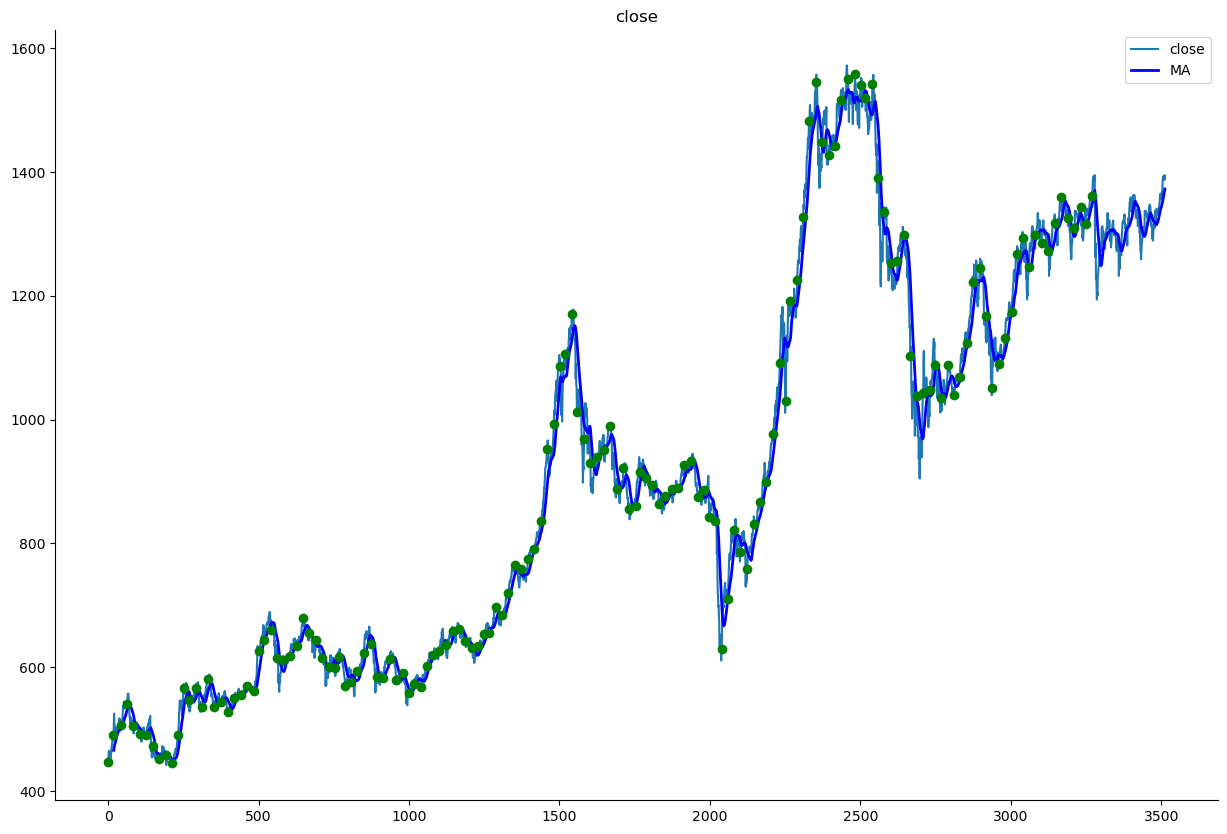

In [22]:

df['close'].plot(kind='line', figsize=(15, 10), title='close')
plt.gca().spines[['top', 'right']].set_visible(False)

df['ma'] = df['close'].rolling(window=20).mean()
plt.plot(df.index, df['ma'], label='MA', color='blue', linewidth=2)
plt.legend()


for t in buyedInfos:
    color = 'green'
    x_value = t.index
    y_value = df['close'][x_value]
    plt.scatter(t.index, y_value, color=color, zorder=3)
    vertical_offset = 0
    plt.text(
        x_value, 
        y_value + vertical_offset, 
        #f"{round(t['maxMoneyCanInvest']):,}" + "-" + f"{round(t['numberOfStockCanBy'])}",
        "",
        fontsize=10, ha='center', va='bottom',
        bbox=dict(facecolor='white', edgecolor='black', boxstyle='round,pad=0.3')
    )

for t in sellInfos:
    color = 'red'
    y_value = df['close'][t.index]
    plt.scatter(t.index, y_value, color=color, zorder=3)
    vertical_offset = -30
    plt.text(
        t.index, y_value + vertical_offset, 
        #f"{round(t['totalSellMoney']):,}" + "-" + f"{round(t['totalSellStock'])}",
        "",
        fontsize=10, ha='center', va='top',
        bbox=dict(facecolor='white', edgecolor='black', boxstyle='round,pad=0.3')
    )

for t in reinvestInfos:
    color = 'yellow'
    y_value = df['close'][t.index]
    plt.scatter(t.index, y_value, color=color, zorder=3)
    vertical_offset = -30
    plt.text(
        t.index, y_value + vertical_offset, 
        #f"{round(t['totalProfitMoney']):,}",
        "",
        fontsize=10, ha='center', va='top',
        bbox=dict(facecolor='white', edgecolor='black', boxstyle='round,pad=0.3')
    )


plt.show()

In [ ]:
firstRow = df.head(1)
firstClose = firstRow['close'].values[0] * 1000
firstDate = firstRow['time'].values[0]
firstDate = pd.Timestamp(firstDate)

lastRow = df.tail(1)
finalClose = lastRow['close'].values[0] * 1000
lastDate = lastRow['time'].values[0]
lastDate = pd.Timestamp(firstDate)

x_range = range(1, 110)
y_range = range(15, 70)


heatMapGrowthRatio = np.zeros((len(x_range), len(y_range)))  # Store results

for i, x in enumerate(x_range):
        print(f'{x}')
        for j, y in enumerate(y_range):
            sellTopStrategy = SellTopStrategy()
            sellTopStrategy.percentSell = 70

            sellTopOfBottomStrategy = SellTopOfBottomStrategy(
                firstLocalBottom = firstClose,
                localRangeDays = x,
                percentSell = y,
            )
            
            reInvestBottomStrategy = ReInvestBottomStrategy()
            reInvestBottomStrategy.percentReinvest = 7

            reInvestBottomOfTopStrategy = ReInvestBottomOfTopStrategy(
                firstLocalTop = firstClose,
                localRangeDays = x,
                decreasePercent = y,
            )
            
            buyIntervalStrategy = BuyIntervalStrategy()
            buyBottomStrategy = BuyBottomStrategy(
                df = df,
                firstLocalTop = firstClose,
                firstLocalTopDate = firstDate,
                localRangeDays = x,
                decreasePercent = y,
            )
            buyMAStrategy = BuyMAStrategy(
                df = df,
                firstLocalAvg = firstClose,
                localRangeDays = 20,
                decreasePercent = 3,
            )
            
            estimateInfo = estimate(df, 8000000, buyIntervalStrategy, sellTopStrategy, reInvestBottomOfTopStrategy, cal_range_close, False)
            allTotalCapital, allTotalFinal, allRatioGrowth, buyedInfos, sellInfos, reinvestInfos = estimateInfo 
            growthRatio = allRatioGrowth
            buyedCount = len(buyedInfos)
            heatMapGrowthRatio[i, j] = growthRatio

# Convert result matrix to DataFrame
growth_df_results = pd.DataFrame(heatMapGrowthRatio, 
                          index=[f"{p}" for p in x_range], 
                          columns=[f"{d}" for d in y_range])

# Create heatmap
plt.figure(figsize=(12, 6))
sns.heatmap(growth_df_results, annot=False, cmap="coolwarm", fmt=".1f")
plt.title("Heatmap of X vs. Y - Estimated Result")
plt.xlabel("X")
plt.ylabel("Y")


1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
18
19
20
21
22
23
24
25
26
27
28
29
30
31
32
33
34
35
36
37
38
39
40
41
42
43
44
45
46
47
48
49
50
51
52
53
54
55
56
57
58
59
60
61
62
63
64
65
66
67
68
69
70
71
72
73
74
75
76
77
78
79
80
81
82


In [153]:
@dataclass
class GrowRatio:
    x: float = 0
    y: float = 0
    z: float = 0
    t: float = 0
    result: float = 0

In [191]:
firstRow = df.head(1)
firstClose = firstRow['close'].values[0] * 1000
firstDate = firstRow['time'].values[0]
firstDate = pd.Timestamp(firstDate)

lastRow = df.tail(1)
finalClose = lastRow['close'].values[0] * 1000
lastDate = lastRow['time'].values[0]
lastDate = pd.Timestamp(firstDate)

x_range = range(0, 100)
y_range = range(15, 35)
z_range = range(7, 8)

growRatios = [] 

for i, x in enumerate(x_range):
    print(x)
    for j, y in enumerate(y_range):
        for k, z in enumerate(z_range):
            buyIntervalStrategy = BuyIntervalStrategy()
            
            sellTopOfBottomStrategy = SellTopOfBottomStrategy(
                firstLocalBottom = firstClose,
                localRangeDays = x,
                percentSell = y,
            )
            
            reInvestBottomStrategy = ReInvestBottomStrategy()
            reInvestBottomStrategy.percentReinvest = z

            # if(days == 0 or percent == 0):
            #     buyMAStrategy = BuyIntervalStrategy()

            # if(profit_percent == 0):
            #     sellTopOfBottomStrategy = None

            # if(reinvest_percent == 0):
            #     reInvestBottomStrategy = None

            estimateInfo = estimate(df, 8000000, buyIntervalStrategy, sellTopOfBottomStrategy, reInvestBottomStrategy, cal_range_close, False)
            allTotalCapital, allTotalFinal, allRatioGrowth, buyedInfos, sellInfos, reinvestInfos = estimateInfo 
            
            growthRatio = allRatioGrowth

            growRatios.append(GrowRatio(
                x = x,
                y = y,
                z = z,
                result = growthRatio
            ))

0
1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
18
19
20
21
22
23
24
25
26
27
28
29
30
31
32
33
34
35
36
37
38
39
40
41
42
43
44
45
46
47
48
49
50
51
52
53
54
55
56
57
58
59
60
61
62
63
64
65
66
67
68
69
70
71
72
73
74
75
76
77
78
79
80
81
82
83
84
85
86
87
88
89
90
91
92
93
94
95
96
97
98
99


In [181]:
growRatios

[GrowRatio(x=0, y=15, z=3, t=0, result=31.45298365228182),
 GrowRatio(x=0, y=15, z=4, t=0, result=34.32117074321137),
 GrowRatio(x=0, y=15, z=5, t=0, result=33.602135953053),
 GrowRatio(x=0, y=15, z=6, t=0, result=33.90659289156163),
 GrowRatio(x=0, y=15, z=7, t=0, result=34.246104848471),
 GrowRatio(x=0, y=15, z=8, t=0, result=33.559664796668834),
 GrowRatio(x=0, y=15, z=9, t=0, result=33.6223278735048),
 GrowRatio(x=0, y=16, z=3, t=0, result=31.419939464368476),
 GrowRatio(x=0, y=16, z=4, t=0, result=34.22780004402938),
 GrowRatio(x=0, y=16, z=5, t=0, result=33.56090924786058),
 GrowRatio(x=0, y=16, z=6, t=0, result=33.75216297233052),
 GrowRatio(x=0, y=16, z=7, t=0, result=34.30070488486396),
 GrowRatio(x=0, y=16, z=8, t=0, result=33.24114676268612),
 GrowRatio(x=0, y=16, z=9, t=0, result=33.67083724582769),
 GrowRatio(x=0, y=17, z=3, t=0, result=31.77463158351228),
 GrowRatio(x=0, y=17, z=4, t=0, result=33.81863310069468),
 GrowRatio(x=0, y=17, z=5, t=0, result=33.16087765516592),


In [193]:
sorted_data = sorted(growRatios, key=lambda x: x.result, reverse=True)
sorted_data

[GrowRatio(x=82, y=34, z=7, t=0, result=160.49898038111178),
 GrowRatio(x=81, y=34, z=7, t=0, result=158.73705174499366),
 GrowRatio(x=85, y=34, z=7, t=0, result=158.030647855172),
 GrowRatio(x=83, y=34, z=7, t=0, result=157.92903547544176),
 GrowRatio(x=84, y=34, z=7, t=0, result=157.92903547544176),
 GrowRatio(x=72, y=30, z=7, t=0, result=156.67488093668152),
 GrowRatio(x=73, y=30, z=7, t=0, result=156.65073974300148),
 GrowRatio(x=74, y=30, z=7, t=0, result=156.65073974300148),
 GrowRatio(x=75, y=30, z=7, t=0, result=156.65073974300148),
 GrowRatio(x=72, y=32, z=7, t=0, result=156.04718652271032),
 GrowRatio(x=86, y=34, z=7, t=0, result=155.5976494297075),
 GrowRatio(x=63, y=29, z=7, t=0, result=155.256348793492),
 GrowRatio(x=62, y=29, z=7, t=0, result=155.08576752647895),
 GrowRatio(x=71, y=29, z=7, t=0, result=154.5711699396278),
 GrowRatio(x=65, y=29, z=7, t=0, result=154.42504764961984),
 GrowRatio(x=66, y=29, z=7, t=0, result=154.42504764961984),
 GrowRatio(x=64, y=29, z=7, t=

In [ ]:
# Convert result matrix to DataFrame
growth_df_results = pd.DataFrame(heatMapGrowthRatioOfSellAndReinvest, 
                          index=[f"{p}%" for p in percent_profit_range], 
                          columns=[f"{d}" for d in percent_reinvest_range])

# Create heatmap
plt.figure(figsize=(12, 6))
sns.heatmap(growth_df_results, annot=False, cmap="coolwarm", fmt=".1f")
plt.title("Heatmap of sell vs. reinvest - Estimated Result")
plt.ylabel("sell")
plt.xlabel("reinvest")

In [73]:
growth_df_results.to_excel("growth_df_results.xlsx", sheet_name="Results", index=True)

In [ ]:
df.to_excel("vn30.xlsx", sheet_name="df", index=True)

In [53]:
df_growthRatio = pd.DataFrame([vars(d) for d in growRatios])

# Save to Excel
df_growthRatio.to_excel("grow_ratios.xlsx", index=False)